# notebook 2 - celltype annotation and beyond

This notebook will introduce you to the process of celltype annotation and give you a brief outlook of some of the analysis you can do with single-cell data in scanpy & besca.


Initial visualization and hand annotation is performed here to show the possible hand-annotation and how Besca is now proposing an automated annotation process, including for mix-cluster. 
This procedure is done in a more straighforward manner on the same dataset in the notebook available there:

https://github.com/bedapub/besca_publication_results/blob/master/hematopoietic/pbmc3k/celltype_annotation_besca_Rc.ipynb


In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
#import necessary python packages
import scanpy as sc #software suite of tools for single-cell analysis in python
import besca as bc #internal BEDA package for single cell analysis
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import scipy

sc.logging.print_header() #output an overview of the software versions that are loaded

scanpy==1.6.0 anndata==0.7.4 umap==0.4.6 numpy==1.19.2 scipy==1.5.2 pandas==1.1.3 scikit-learn==0.23.2 statsmodels==0.12.0 python-igraph==0.8.2 leidenalg==0.8.2


In [4]:
# Will only print error. 
# Warning (eg genes not found) are ignored.
sc.settings.verbosity=0

In [5]:
from IPython.display import HTML
task = "<style>div.task { background-color: #ffc299; border-color: #ff944d; border-left: 7px solid #ff944d; padding: 1em;} </style>"
HTML(task)

In [6]:
tag = "<style>div.tag { background-color: #99ccff; border-color: #1a8cff; border-left: 7px solid #1a8cff; padding: 1em;} </style>"
HTML(tag)

In [7]:
FAIR = "<style>div.fair { background-color: #d2f7ec; border-color: #d2f7ec; border-left: 7px solid #2fbc94; padding: 1em;} </style>"
HTML(FAIR)

## Dataset

Here we will reload our previously completely processed dataset.

In [8]:
#adata = sc.read('/tmp/adata_pbmc_FRESH_processed.h5ad')
adata = bc.datasets.pbmc3k_filtered()



In [9]:
adata

AnnData object with n_obs × n_vars = 2504 × 1719
    obs: 'CELL', 'percent_mito', 'experiment', 'n_counts', 'n_genes', 'leiden'
    var: 'ENSEMBL', 'SYMBOL', 'n_cells', 'total_counts', 'frac_reads'
    uns: 'experiment_colors', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

## Celltype annotation

### Manual cell annotation based on the expression of known marker genes

In [10]:
#define genes (in future you will be able to access genesets from a central database GEMS)
b_cells = ['CD19', 'CD79A', 'MS4A1']
t_cells = ['CD3E', 'CD3G', 'CD3D']
t_cell_subsets = ['CD4', 'CD8A', 'CD8B']
naive_t_cell = ['SELL', 'CCR7', 'IL7R']
myeloid_cells = ['S100A8', 'S100A9', 'CST3']
monocytes = ['FCGR3A', 'FCGR3B', 'CD14'] #FCGR3A/B = CD16
dendritic_cells = ['FCER1A', 'ITGAM', 'ITGAX'] #ITGAM = CD11b #ITGAX= CD11c 
NK_cells = ['NCAM1', 'NKG7', 'CD3G']

<div class="tag">
We always use the HGNC symbols of genes as the main annotation type in the AnnData object since they are the most practical to work with. In addition, the ensemble IDs of all genes is saved in adata.var according to our FAIR standard and always written out since Ensembl IDs stay very robust over time.

Based on the dataset the marker genes that are expressed may vary strongly.
    
</div>

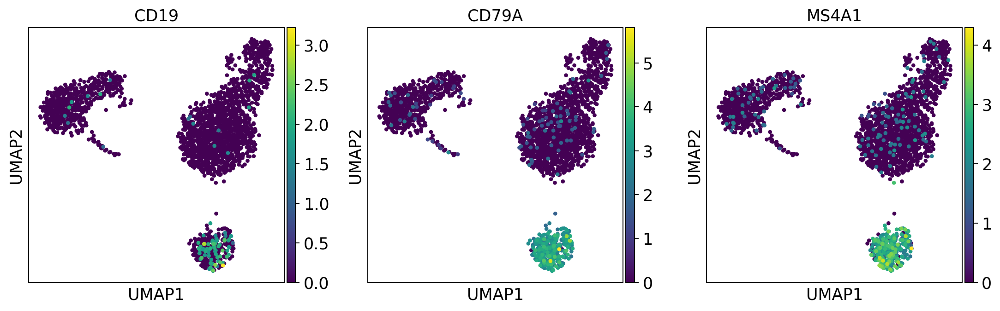

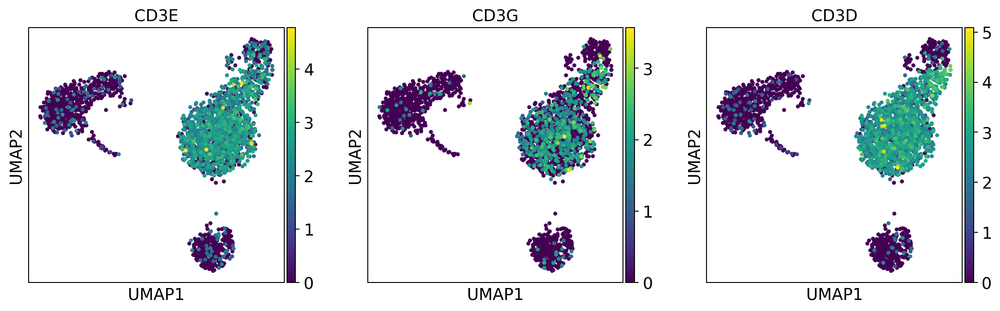

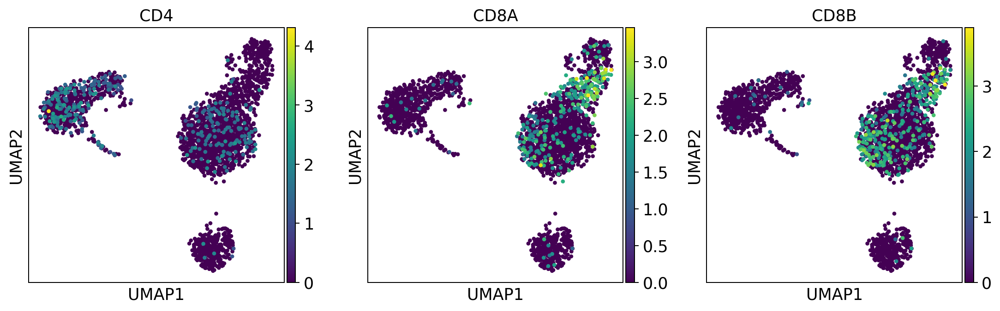

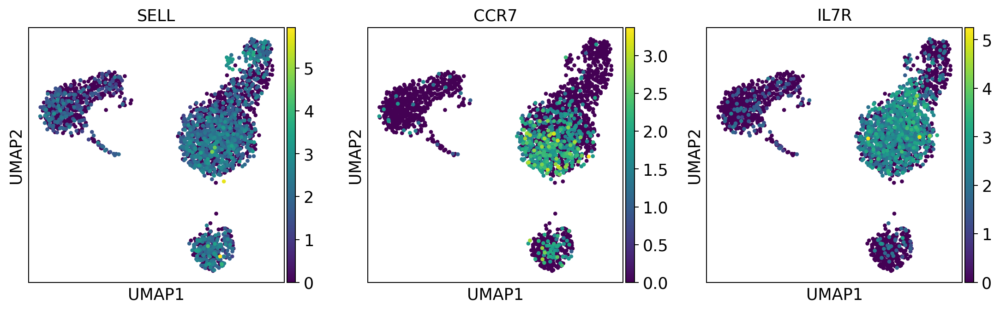

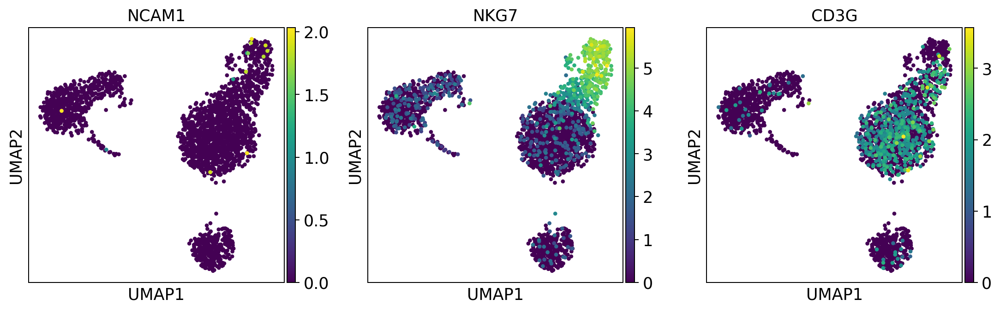

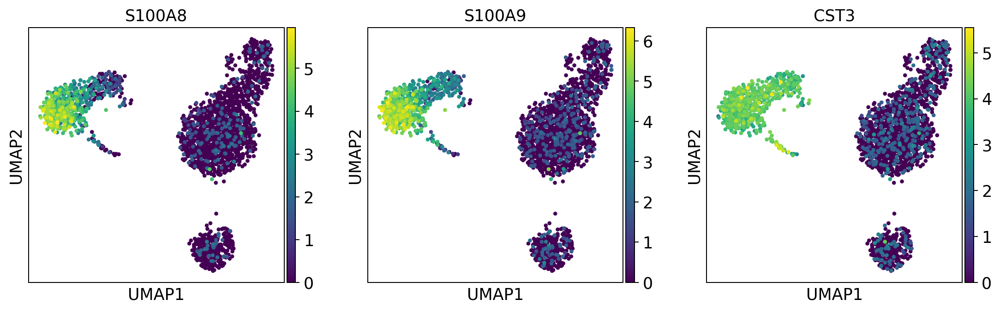

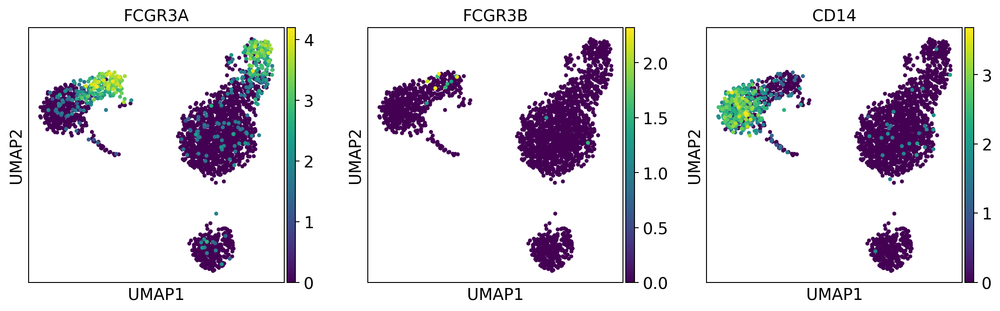

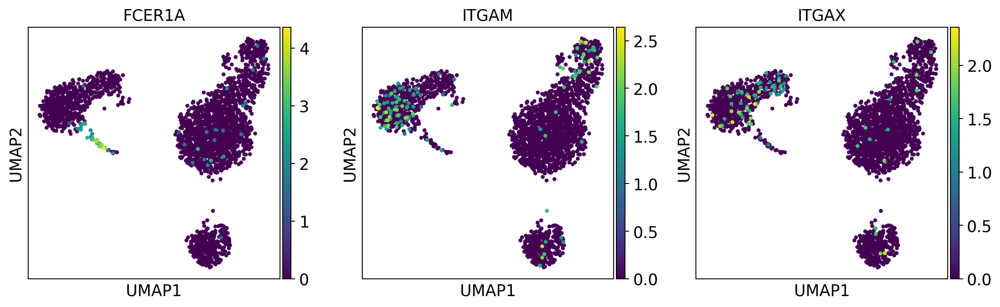

In [11]:
sc.settings.set_figure_params(dpi=90)
#visualize the gene expression as an overlay of the umap
#(this way you can visually identify the clusters with a high expression))
sc.pl.umap(adata, color = b_cells, color_map = 'viridis', ncols = 3)
sc.pl.umap(adata, color = t_cells, color_map = 'viridis', ncols = 3)
sc.pl.umap(adata, color = t_cell_subsets, color_map = 'viridis', ncols = 3)
sc.pl.umap(adata, color = naive_t_cell, color_map = 'viridis', ncols = 3)
sc.pl.umap(adata, color = NK_cells,  color_map = 'viridis',ncols = 3)
sc.pl.umap(adata, color = myeloid_cells,  color_map = 'viridis',ncols = 3)
sc.pl.umap(adata, color = monocytes, color_map = 'viridis', ncols = 3)
sc.pl.umap(adata, color = dendritic_cells, color_map = 'viridis', ncols = 3)

<div class="tag">
Per default scanpy plots the gene expression values saved in adata.raw (this means log1p(cp10k)). This is the reason that we can visualize all of these genes even if they are not contained in the highly variable genes.
</div>

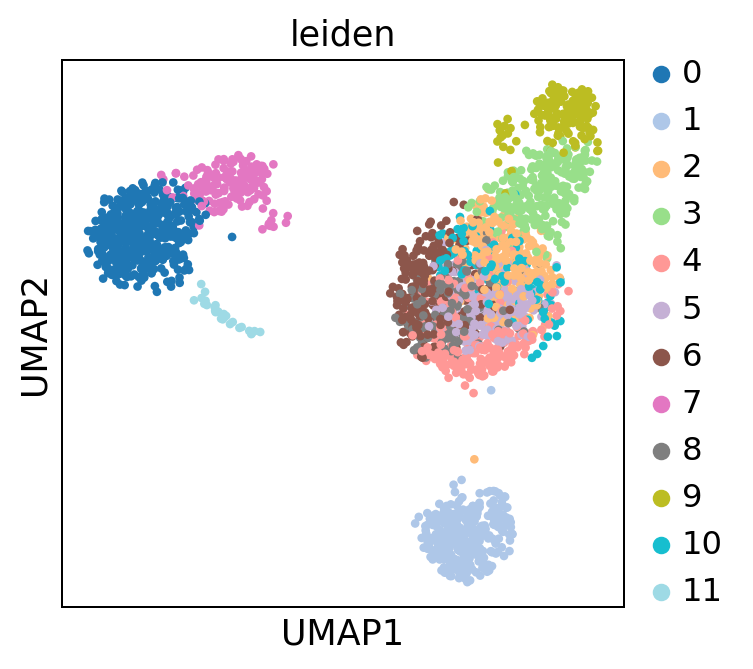

In [12]:
sc.pl.umap(adata, color = 'leiden', palette = 'tab20')

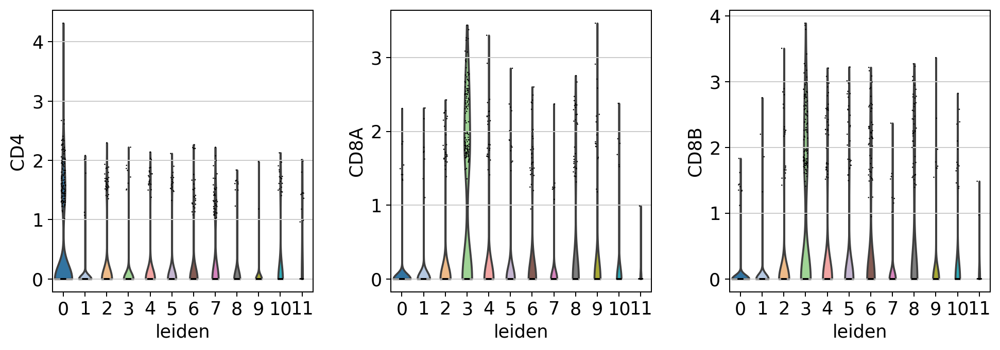

In [13]:
sc.pl.violin(adata, keys= t_cell_subsets, groupby= 'leiden', scale = 'count' )

In [14]:
#write down new cluster names (important order needs to be equivalent to above)
#will label the cell types:

new_cluster_names = ['CD14+ monocyte', #0
                     'B-cell', #1
                     'Mix T-cell', #2
                     'CD8 T-cell', #3
                     'Mix T-cell', #4
                     'Mix T-cell', #5
                     'CD8 T-cell', #6
                     'FCGR3A+ monocyte', #7
                     'CD8 T-cell', #8
                     'NK cells', #9
                     'Mix T-cell', #10
                     'pDC'] #1

bc.tl.annotate_cells_clustering(adata=adata, clustering_label='leiden', new_annotation_label='manual_annotation', new_cluster_labels=new_cluster_names)

<div class="tag">
There are also more advanced methods of cell annotation where mixed clusters (i.e. clusters that contain more than one celltype) can be reclustered seperately and then annoated. Please refer to besca's documentation for more information. 
</div>

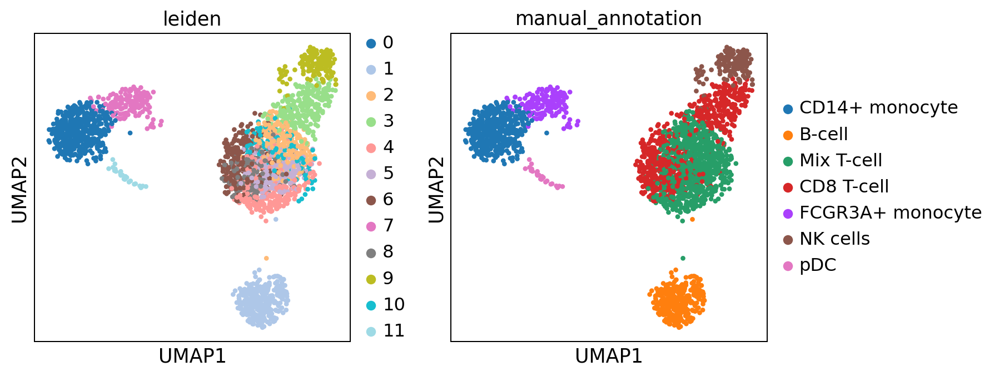

In [15]:
sc.pl.umap(adata, color = ['leiden', 'manual_annotation'], wspace = 0.2)

<div class="tag">
Several clusters have been combined into one celltype. Here only a very rudimentary celltype annotation was performed. Depending on the dataset and the type of analysis this can become far more complex and detailled. 
    
We propose to use a an automated annotation methods to decipher the cluster in an **un-bias** way
    
    
This steps requires to expore initial labelling. This steps within besca will export:
    
    + frac_pos, computing for each gene and cluster the fraction of cells that show a gene expression.
    + average.gct, computing for each gene the average expression per cluster
    
</div>

<div class="fair">
write out required annotation  
`bc.export.labeling(adata=adata, outpath=FILEPATH_TO_FOLDER, column  = 'leiden')`
</div>

In [16]:
bc.export.labeling(adata=adata, outpath='dataset_export/', column  = 'leiden')

mapping of cells to  leiden exported successfully to cell2labels.tsv
average.gct exported successfully to file
fract_pos.gct exported successfully to file


### Hierarchical signature-enrichment based approach for cell type annotation for Hematopoeitic cells


Besca offers a  hierarchical signature-enrichment based approach for cell type annotation.
The initial hierarchy can be visualized below

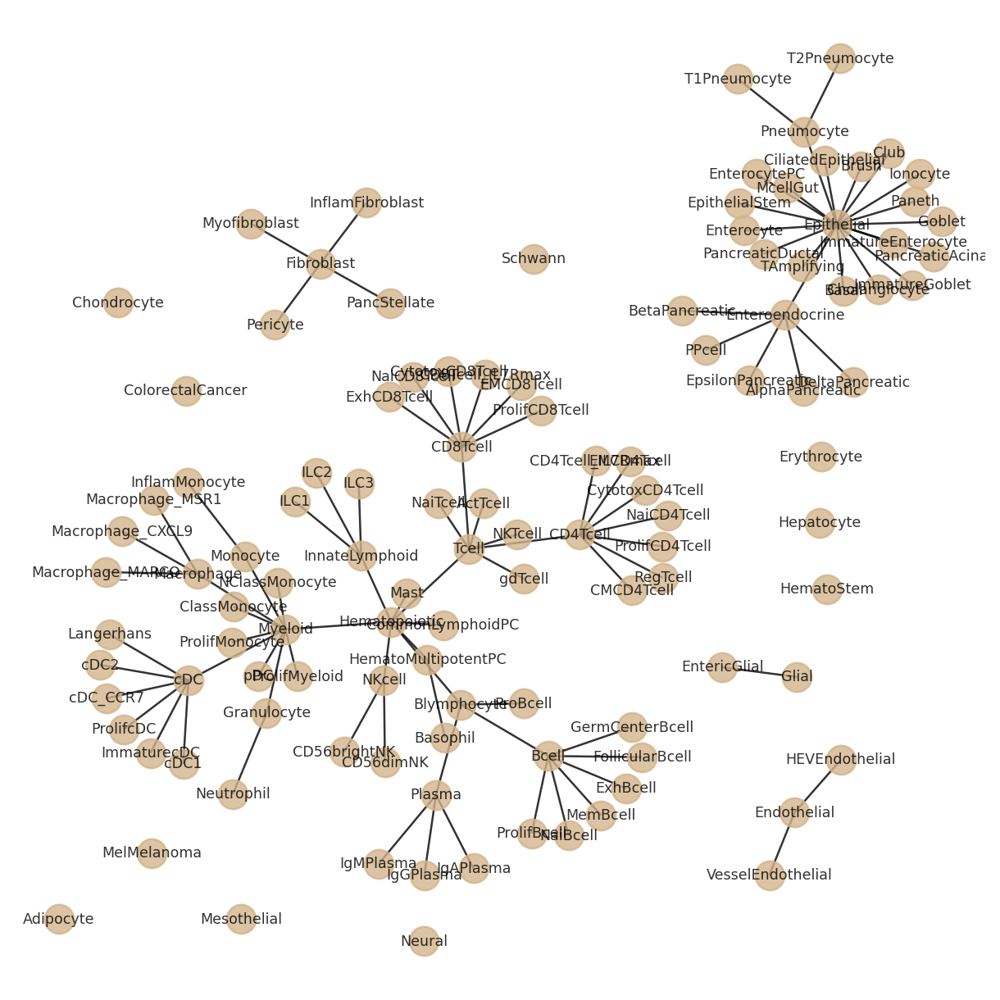

In [17]:
import pkg_resources

config_file = pkg_resources.resource_filename('besca', 'datasets/genesets/CellNames_scseqCMs6_config.tsv')
plt = bc.pl.nomenclature_network(config_file)
plt.show()

## Signature loading and scoring

We load signature directly importing a gmt file.
In case of connection to a GemS database, it is possible to use the GeMs signature loader.


In [18]:
sigconfig,levsk=bc.tl.sig.read_annotconfig(config_file)

In [19]:
gmt_file_anno = pkg_resources.resource_filename('besca', 'datasets/genesets/CellNames_scseqCMs6_sigs.gmt')


mymarkers = bc.tl.sig.read_GMT_sign(gmt_file_anno,directed=False)
mymarkers = bc.tl.sig.filter_siggenes(adata, mymarkers)


bc.tl.sig.combined_signature_score(adata, gmt_file_anno, verbose=False)
#




In [20]:
sc.settings.set_figure_params(dpi=50)
scores = [x for x in adata.obs.columns if 'scanpy' in x]
sc.pl.umap(adata, color= scores, color_map = 'viridis')

<div class="tag">


Signature can be observed in detailled to assess manually the cell types to which assign the different clusters.
However Besca offers to use a signature-based hierarchical annotation to build on know relations (see network above). 
This annotation is based on the mann whitney scoring of the positive fraction of cell and signatures provided.
Additionally, this signature-based annotation procedures will then use a consistent labelling of the dataset and cell-types, facilitating cross-study comparisons in the futur.
    
</div>

In [21]:

mymarkers['Ubi'] = ['B2M','ACTB', 'GAPDH'] ### used for cutoff adjustment to individual dataset, can be modified

f=pd.read_csv("dataset_export/fract_pos.gct",sep="\t",skiprows=2)
df=bc.tl.sig.score_mw(f,mymarkers)

myc=np.median(df.loc['Ubi',:]*0.5) ### Set a cutoff based on Ubi and scale with values from config file

One can observe the resulting log10(pvalues) obtained

In [22]:
df.iloc[0:3,0:7]


,6,0,7,9,8,11,1
Bcell,10.5977,4.33419,7.80649,1.49797,2.68703,7.80042,69.0433
Fibroblast,0.789622,0.239568,1.19473,0.942461,0.285982,0.290622,0.155626
Endothelial,1.71538,0.904445,9.77757,0.814998,0.461955,6.4328,0.116507


In [23]:
#Cluster attribution based on cutoff
df=df.drop('Ubi')
sigscores={}
for mysig in list(df.index):
    sigscores[mysig]=bc.tl.sig.getset(df,mysig,sigconfig.loc[mysig,'Cutoff']*myc)

In [24]:
sigconfig.loc["CD8Tcell","Cutoff"]=1.2
# RECOMPUTING SIG SCORE WITH NEW CUTOFF
sigscores={}
for mysig in list(df.index):
    sigscores[mysig]=bc.tl.sig.getset(df,mysig,sigconfig.loc[mysig,'Cutoff']*myc)
    
    
cnames=bc.tl.sig.make_anno(df,sigscores,sigconfig,levsk)
cnames

,celltype0,celltype1,celltype2,celltype3
6,Hematopoietic,Tcell,CD8Tcell,NaiCD8Tcell
0,Hematopoietic,Myeloid,ClassMonocyte,ClassMonocyte
7,Hematopoietic,Myeloid,NClassMonocyte,NClassMonocyte
9,Hematopoietic,NKcell,CD56dimNK,CD56dimNK
8,Hematopoietic,Tcell,CD8Tcell,NaiCD8Tcell
11,Hematopoietic,Myeloid,cDC,cDC2
1,Hematopoietic,Blymphocyte,Bcell,NaiBcell
3,Hematopoietic,Tcell,CD8Tcell,CytotoxCD8Tcell
10,Hematopoietic,Tcell,CD4Tcell,NaiCD4Tcell
2,Hematopoietic,Tcell,CD4Tcell,EMCD4Tcell


In [25]:
label_files = pkg_resources.resource_filename('besca', '/datasets/nomenclature/CellTypes_v1.tsv')

cnamesDBlabel = bc.tl.sig.obtain_dblabel( label_files, cnames )
cnamesDBlabel

,celltype0,celltype1,celltype2,celltype3
6,hematopoietic cell,T cell,"CD8-positive, alpha-beta T cell","naive thymus-derived CD8-positive, alpha-beta ..."
0,hematopoietic cell,myeloid leukocyte,classical monocyte,classical monocyte
7,hematopoietic cell,myeloid leukocyte,non-classical monocyte,non-classical monocyte
9,hematopoietic cell,natural killer cell,cytotoxic CD56-dim natural killer cell,cytotoxic CD56-dim natural killer cell
8,hematopoietic cell,T cell,"CD8-positive, alpha-beta T cell","naive thymus-derived CD8-positive, alpha-beta ..."
11,hematopoietic cell,myeloid leukocyte,myeloid dendritic cell,CD1c-positive myeloid dendritic cell
1,hematopoietic cell,lymphocyte of B lineage,B cell,naive B cell
3,hematopoietic cell,T cell,"CD8-positive, alpha-beta T cell","CD8-positive, alpha-beta cytotoxic T cell"
10,hematopoietic cell,T cell,"CD4-positive, alpha-beta T cell","naive thymus-derived CD4-positive, alpha-beta ..."
2,hematopoietic cell,T cell,"CD4-positive, alpha-beta T cell","effector memory CD4-positive, alpha-beta T cell"


In [26]:
adata.obs['celltype0']=bc.tl.sig.add_anno(adata,cnamesDBlabel,'celltype0','leiden')
adata.obs['celltype1']=bc.tl.sig.add_anno(adata,cnamesDBlabel,'celltype1','leiden')
adata.obs['celltype2']=bc.tl.sig.add_anno(adata,cnamesDBlabel,'celltype2','leiden')
adata.obs['celltype3']=bc.tl.sig.add_anno(adata,cnamesDBlabel,'celltype3','leiden')

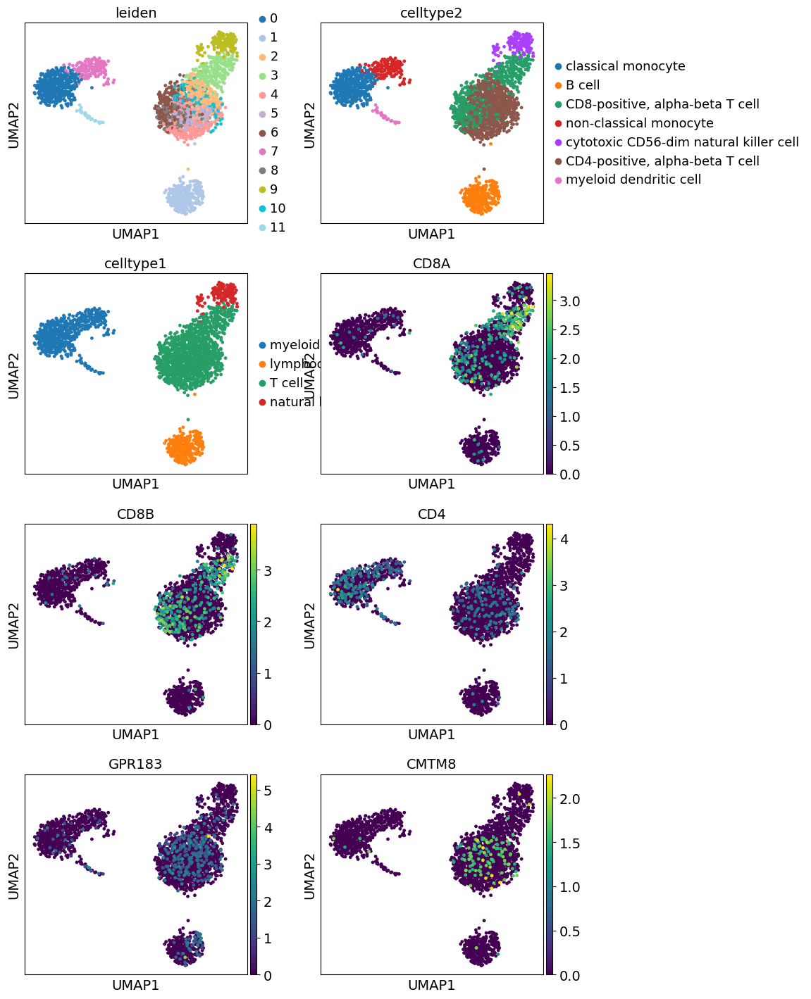

In [27]:
sc.pl.umap(adata,color=['leiden','celltype2', 'celltype1', 
                        'CD8A', 'CD8B', # CD8 T cell markers
                        'CD4' ,    'GPR183', 'CMTM8' # CD4 t cell markers
                       ], ncols=2) #,'celltype3'

<div class="tag">
Here we believe some clusters of T cells are still mixed and that a more refined annotation can be done if recluster the lymphocytes. 
This procedure is applied below
</div>

## Reclustering Lymphocytes



In [28]:
adata.obs['leiden_original'] = adata.obs['leiden'].copy()


In [29]:
adata_rc = bc.tl.rc.recluster ( adata, celltype_label = 'celltype1', 
                               celltype= ('T cell',  'natural killer cell'), resolution=1.3)

In total 1409 highly variable genes selected within cluster


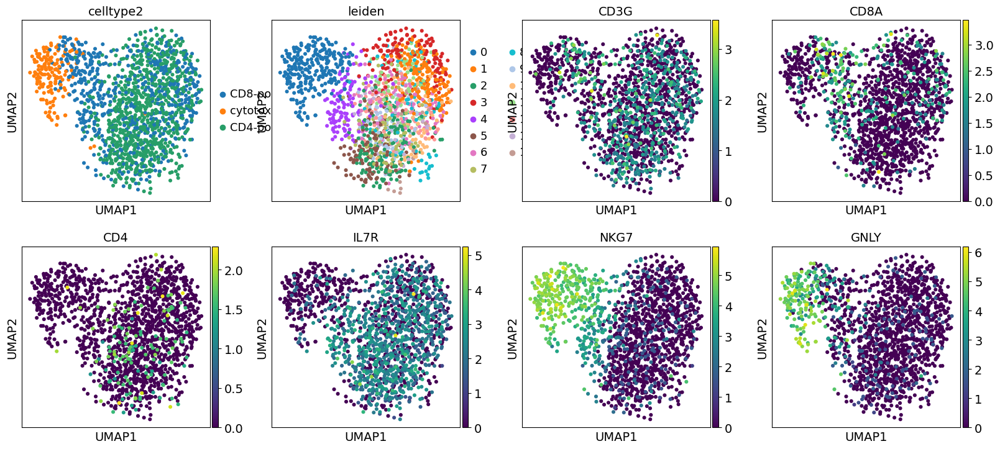

In [30]:
sc.pl.umap( adata_rc, color = ['celltype2','leiden', 
                              # Some markers
                              'CD3G', 'CD8A', 'CD4', 'IL7R', 'NKG7', 'GNLY'])

<div class="tag">
Exporting the additional labelling allows to regenerate frac_pos required file for the annotation function.
</div>

In [31]:
adata_rc = bc.st.additional_labeling(adata_rc, 'leiden', 'Leiden_Reclustering', 'Leiden Reclustering on Lymphocytes', 'BescaTutorial', 'dataset_export')

rank genes per label calculated using method wilcoxon.
mapping of cells to  leiden exported successfully to cell2labels.tsv
average.gct exported successfully to file
fract_pos.gct exported successfully to file
labelinfo.tsv successfully written out
dataset_export/labelings/Leiden_Reclustering/WilxRank.gct written out
dataset_export/labelings/Leiden_Reclustering/WilxRank.pvalues.gct written out
dataset_export/labelings/Leiden_Reclustering/WilxRank.logFC.gct written out


In [32]:
mymarkers['Ubi'] = ['B2M','ACTB', 'GAPDH'] 
clusters = 'Leiden_Reclustering'
f=pd.read_csv('dataset_export' + "/labelings/"+clusters+"/fract_pos.gct",sep="\t",skiprows=2)
df=bc.tl.sig.score_mw(f,mymarkers)
myc=np.median(df.loc['Ubi',:]*0.5) ### Set a cutoff based on Ubi and scale with values from config file

In [33]:
# RECOMPUTING SIG SCORE WITH NEW CUTOFF
df=df.drop('Ubi')
sigscores={}
for mysig in list(df.index):
    sigscores[mysig]=bc.tl.sig.getset(df,mysig,sigconfig.loc[mysig,'Cutoff']*myc)
    #sigscores[mysig]=bc.tl.sig.getset(df,mysig,10)

In [34]:
toExclude = [x  for x in levsk[1] if not x == 'Tcell' and not x == 'NKcell']

cnames=bc.tl.sig.make_anno(df,sigscores,sigconfig,levsk,  toexclude= toExclude)

cnamesDBlabel = bc.tl.sig.obtain_dblabel(label_files, cnames )


adata_rc.obs['celltype0']=bc.tl.sig.add_anno(adata_rc,cnamesDBlabel,'celltype0','leiden')
adata_rc.obs['celltype2']=bc.tl.sig.add_anno(adata_rc,cnamesDBlabel,'celltype2','leiden')
adata_rc.obs['celltype3']=bc.tl.sig.add_anno(adata_rc,cnamesDBlabel,'celltype3','leiden')

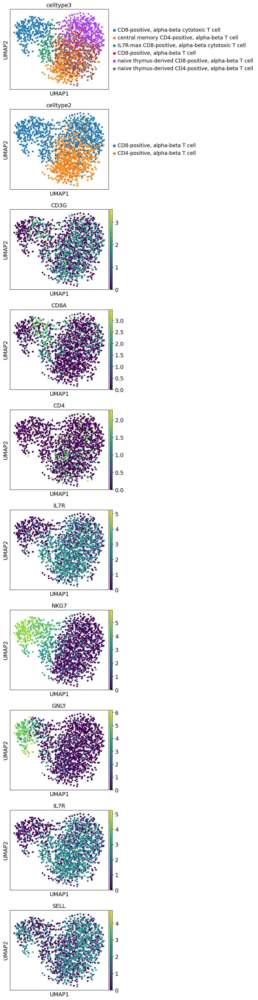

In [35]:
sc.pl.umap(adata_rc,color=['celltype3', 'celltype2',
                           'CD3G', 'CD8A', 'CD4', 'IL7R', 'NKG7', 'GNLY', #, 'S100A'
                           'IL7R', 'SELL'
                          ], 
           ncols=1)

In [36]:
names_2 = []
names_3 = []
for i in range( cnames.shape[0]) :
    # Orderigng lexo. order
    names_2 += [cnamesDBlabel['celltype2'][str(i)]]
    names_3 += [cnamesDBlabel['celltype3'][str(i)]]

In [37]:
bc.tl.rc.annotate_new_cellnames( adata, adata_rc, names = names_2, new_label='celltype2', method = 'leiden')

bc.tl.rc.annotate_new_cellnames( adata, adata_rc, names = names_3, new_label='celltype3', method = 'leiden')

NOTE: overwriting labels for the selected cells saved in adata.obs.celltype2 with the new labels
NOTE: overwriting labels for the selected cells saved in adata.obs.celltype3 with the new labels


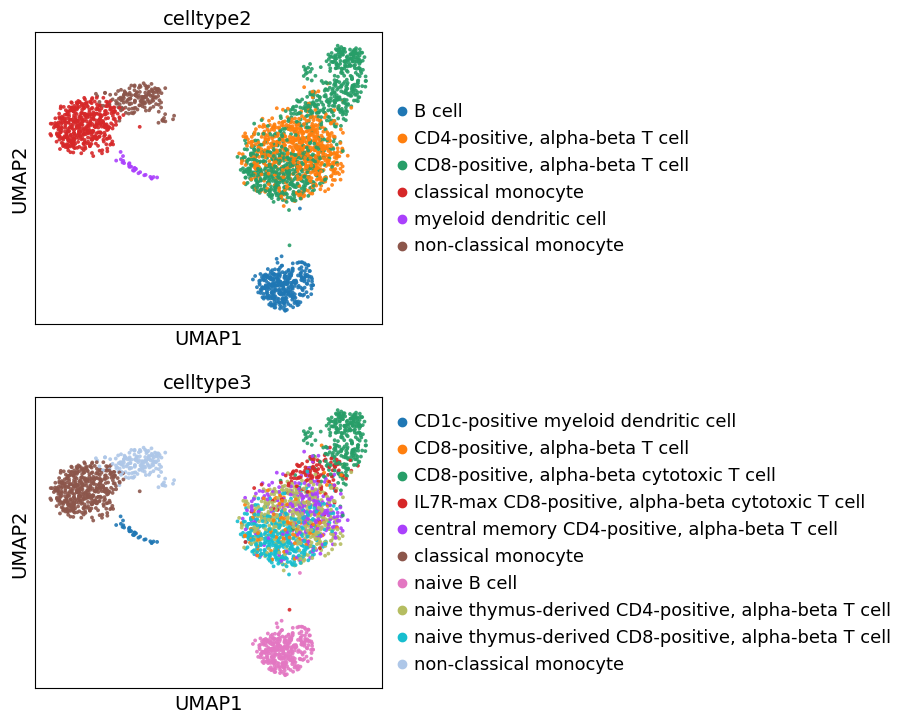

In [38]:
sc.pl.umap(adata,color=['celltype2',
                       'celltype3'], ncols=1, alpha= 0.9, size= 30) 

<div class="tag">
Here we write out the celltype annotation so that we can use reload it in later analysis steps. There is a corresponding besca function for reloading the annotation.
</div>

In [39]:
#save AnnData Object for comparision purposes
adata.write('dataset_export/data_pbmc_processed_annotated.h5ad')

## unbiased marker genes for each cluster

In [41]:
#perform differential gene expression between each cluster and all other cells using scanpy
sc.tl.rank_genes_groups(adata, groupby='celltype3')

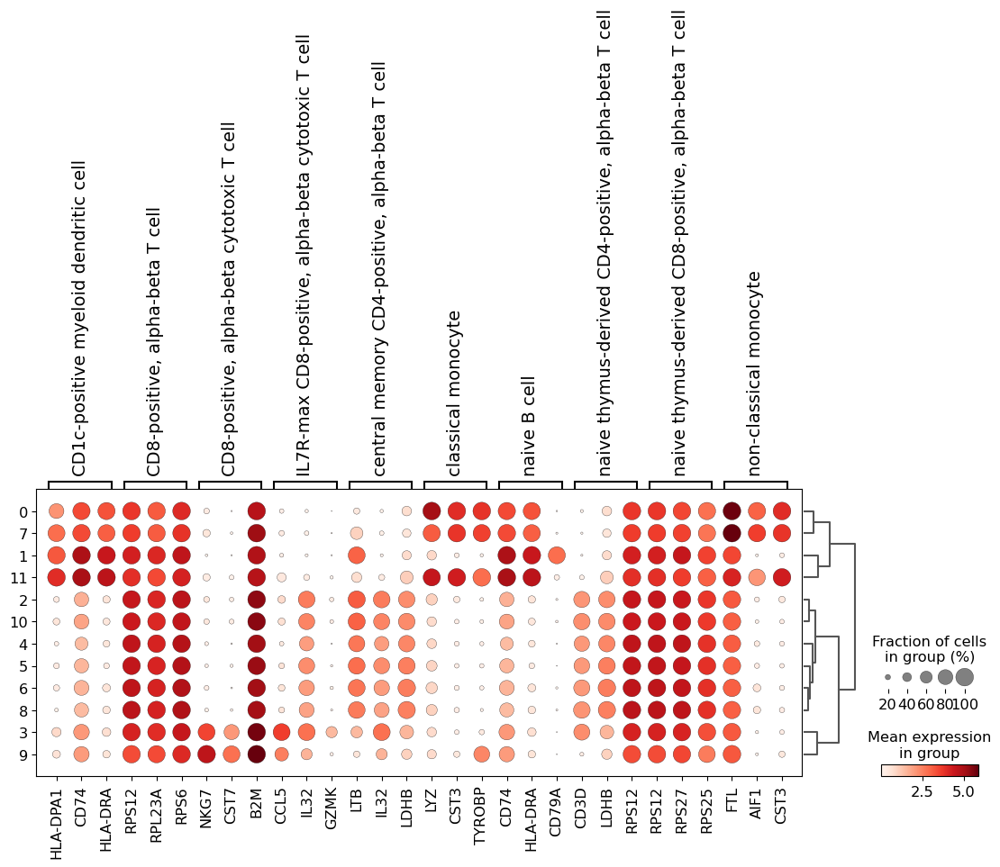

In [42]:
#visualize the top 3 marker genes as a dot plot
sc.pl.rank_genes_groups_dotplot(adata, n_genes=3, groupby = 'leiden')

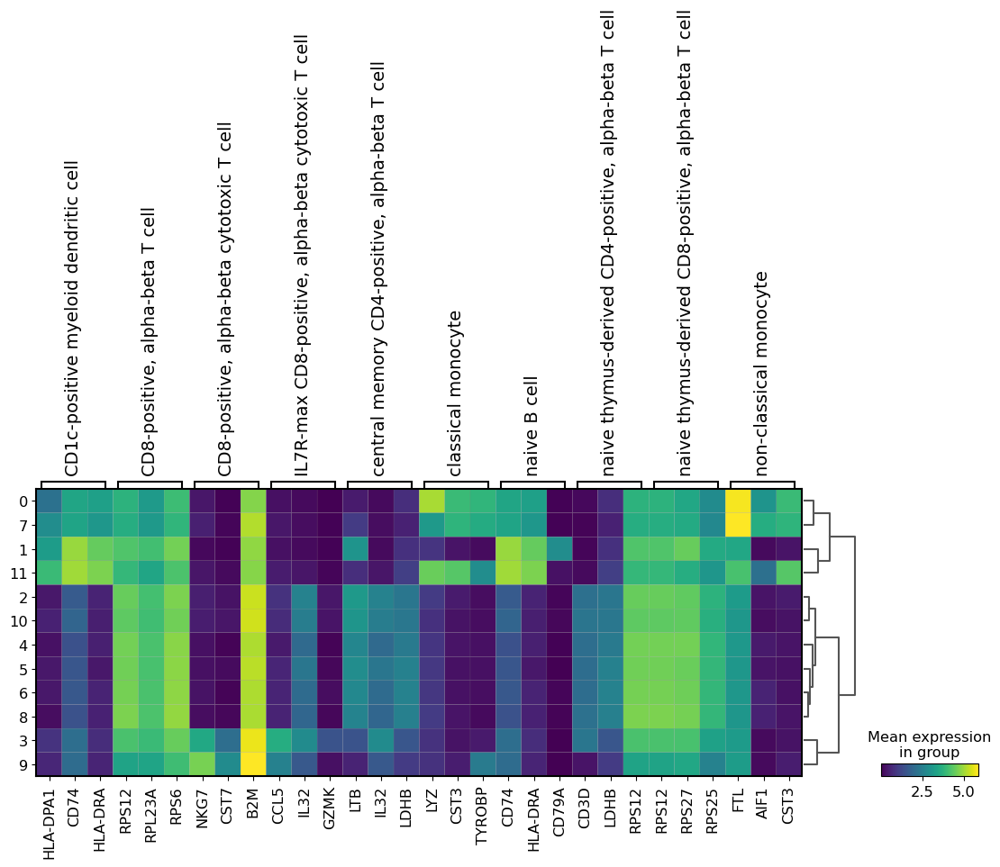

In [43]:
sc.pl.rank_genes_groups_matrixplot(adata, n_genes=3, use_raw=True, groupby = 'leiden')

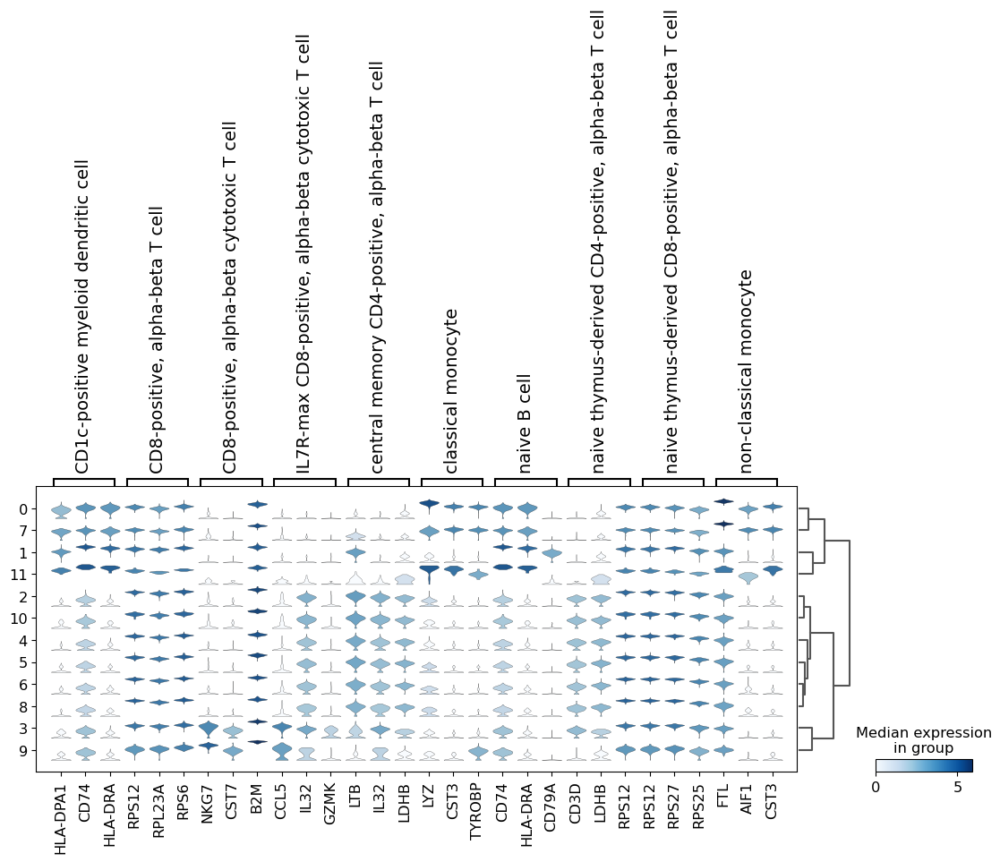

In [44]:
sc.pl.rank_genes_groups_stacked_violin(adata, n_genes=3, groupby='leiden')

## Celltype Quantification

In [45]:
#counts per celltype
data = bc.tl.count_occurrence(adata, add_percentage=True, count_variable='celltype3')
display(data)

,Counts,Percentage
classical monocyte,438,17.49
"naive thymus-derived CD4-positive, alpha-beta T cell",414,16.53
"naive thymus-derived CD8-positive, alpha-beta T cell",391,15.62
naive B cell,317,12.66
"CD8-positive, alpha-beta cytotoxic T cell",271,10.82
"central memory CD4-positive, alpha-beta T cell",267,10.66
non-classical monocyte,159,6.35
"IL7R-max CD8-positive, alpha-beta cytotoxic T cell",118,4.71
"CD8-positive, alpha-beta T cell",100,3.99
CD1c-positive myeloid dendritic cell,29,1.16


(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'classical monocyte'),
  Text(1, 0, 'naive thymus-derived CD4-positive, alpha-beta T cell'),
  Text(2, 0, 'naive thymus-derived CD8-positive, alpha-beta T cell'),
  Text(3, 0, 'naive B cell'),
  Text(4, 0, 'CD8-positive, alpha-beta cytotoxic T cell'),
  Text(5, 0, 'central memory CD4-positive, alpha-beta T cell'),
  Text(6, 0, 'non-classical monocyte'),
  Text(7, 0, 'IL7R-max CD8-positive, alpha-beta cytotoxic T cell'),
  Text(8, 0, 'CD8-positive, alpha-beta T cell'),
  Text(9, 0, 'CD1c-positive myeloid dendritic cell')])

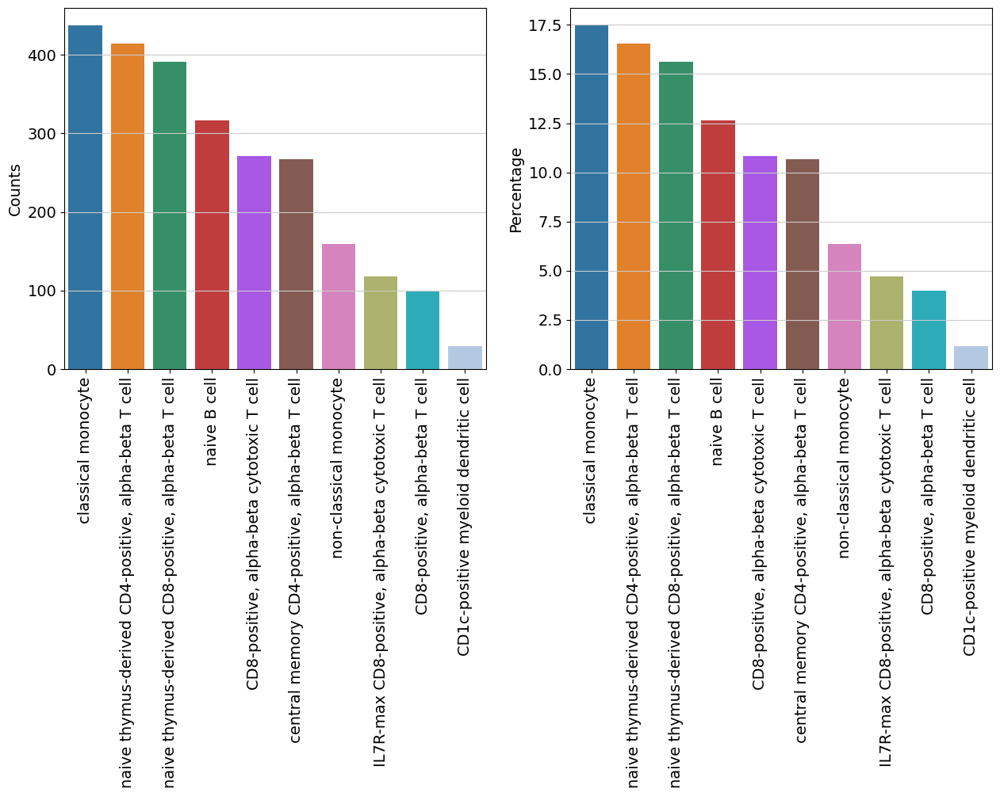

In [46]:
#generate a basic bar plot of the table above
fig = plt.figure(figsize=(15,6))

#visualize distribution before logarithmization
ax1 = fig.add_subplot(1, 2, 1)
ax1 = sns.barplot(data = data, x = data.index.tolist(), y = 'Counts' )
plt.xticks(rotation=90)

#visualize distribution after logarithmization
ax2 = fig.add_subplot(1, 2, 2)
ax2 = sns.barplot(data = data, x = data.index.tolist(), y = 'Percentage' )
plt.xticks(rotation=90)